# 02. Baseline pipeline: contract, split ? leakage-control

**????.** ????????? ??????????? ?????????? ?? `raw_data/`: ???? ??????????, ??????? ???????? ?? explicit anchor, split ? baseline. ??????? ?? ?????? ??????? ??????? ?????? ????, ? ???????? ??????????????? ?????? `dashboard.final_data_pipeline`.


In [1]:
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dashboard.final_data_pipeline import PROJECT_ROOT, SEED, artifact_paths, run_pipeline

random.seed(SEED)
np.random.seed(SEED)
RAW_DATA = PROJECT_ROOT / "raw_data"
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
PATHS = artifact_paths(ARTIFACT_DIR)
print(f"raw_data: {RAW_DATA}")
print(f"artifact_dir: {ARTIFACT_DIR}")


raw_data: C:\Main\DGTU\ВКР\Diploma\raw_data
artifact_dir: C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts


## 1. ?????? strict/intensity contract

Contract ???????? ???????? ?? `raw_data`: raw logs, KPI-?????, ????????? ????? `10s`, macro-???????? ????? `60s` ? `gap10` ?? ???????????? ???????. ??? failure-run ???????????? ?????? explicit anchors ?? ?????; ????, ?????????? ??????? ?????? ? anchor, ??????????? ?? ????????.


In [2]:
report = run_pipeline(raw_data=RAW_DATA, artifact_dir=ARTIFACT_DIR)
print(json.dumps(report["written_files"], ensure_ascii=False, indent=2))


{
  "contract": "dashboard\\artifacts\\contract\\strict_intensity_contract.csv.gz",
  "contract_summary": "dashboard\\artifacts\\contract\\strict_contract_summary.csv",
  "baseline_summary": "dashboard\\artifacts\\reports\\baseline_summary_metrics.json",
  "baseline_comparison": "dashboard\\artifacts\\reports\\baseline_comparison_compact.csv",
  "baseline_predictions": "dashboard\\artifacts\\reports\\baseline_predictions.csv.gz",
  "pipeline_report": "dashboard\\artifacts\\reports\\final_data_pipeline_report.json"
}


**????????? ?????.** ????? ???? ?????? ???? downstream-?????? ???????? ???? ???????????? ????: `dashboard/artifacts/contract/strict_intensity_contract.csv.gz`. ?????? ????????????????? ????????? ?? ???????? ?????? ????????? ???????.


## 2. Split ? ??????? ????????

?????????, ??? split ?? ????????? ?????????? ???? ?????? run ? ??? ??? ??????? ????? ?? ?????????. Binary-???? ????? ??? ??????? ????????, intensity-???? ? ??? ???????? ?????????? ????? ?? ??????? ?? ???????.


,split,rows,runs,workloads,warning_share,risk_share,both_modalities
0,test,468,51,4,0.185897,0.081197,0.666667
1,train,1407,114,9,0.285004,0.087420,0.653873
2,validation,503,53,3,0.495030,0.155070,0.968191


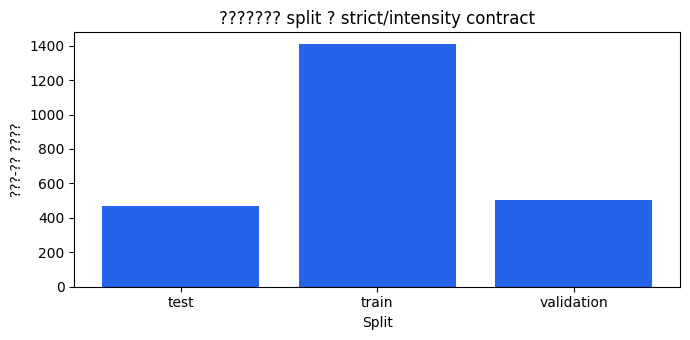

In [3]:
contract = pd.read_csv(PATHS.contract_path, parse_dates=["window_ts", "window_end"], low_memory=False)
split_summary = (
    contract.groupby("split")
    .agg(
        rows=("run_id", "size"),
        runs=("run_id", "nunique"),
        workloads=("workload", "nunique"),
        warning_share=("y_warning", "mean"),
        risk_share=("y_risk", "mean"),
        both_modalities=("has_both_modalities", "mean"),
    )
    .reset_index()
)
display(split_summary)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(split_summary["split"], split_summary["rows"], color="#2563eb")
ax.set_title("??????? split ? strict/intensity contract")
ax.set_ylabel("???-?? ????")
ax.set_xlabel("Split")
plt.tight_layout()
plt.show()


**??? ????????.** ????????????? ????, ???????? ? ??????? ????? ?? split.  
**????????? ?????.** ????????? ??????? ????? ???????????????? ?????? ?????? ? ????? positive-???? ? ????????? ????? ????????????; ????? ??????? score ????? ????????? ?????????? ?????????? ??? ???????? ? anchor.


## 3. Baseline ??? ?????? ???????

Baseline ?? ???????? ????????? ????????. ?? ?????, ????? ?????????, ???? ?? ? contract ????????? ?????? ? ??? ????? ???? log-only, KPI-only, availability-only ? ??????? fused ??????? ?? ??? ?? split.


,target,baseline,average_precision,roc_auc,precision,recall,f1,n,positives,prevalence
0,y_risk,log-only,0.233249,0.776040,0.106312,0.842105,0.188791,468,38,0.081197
1,y_risk,fused,0.173531,0.654835,0.092105,0.736842,0.163743,468,38,0.081197
2,y_risk,kpi-only,0.166604,0.647674,0.098940,0.736842,0.174455,468,38,0.081197
3,y_risk,availability-only,0.075195,0.334700,0.076577,0.894737,0.141079,468,38,0.081197
4,y_warning,log-only,0.349033,0.672580,0.239544,0.724138,0.360000,468,87,0.185897
5,y_warning,fused,0.336771,0.738740,0.317073,0.298851,0.307692,468,87,0.185897
6,y_warning,kpi-only,0.330834,0.735210,0.344262,0.241379,0.283784,468,87,0.185897
7,y_warning,availability-only,0.177248,0.333303,0.020690,0.034483,0.025862,468,87,0.185897


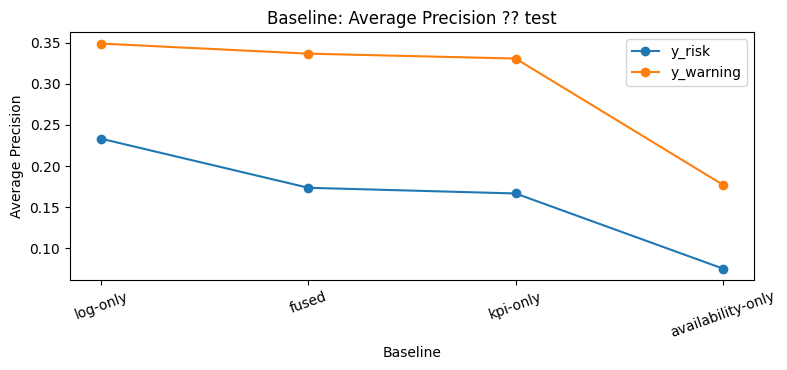

In [4]:
baseline = pd.read_csv(PATHS.baseline_comparison_path)
compact = baseline.sort_values(["target", "average_precision"], ascending=[True, False])
display(compact)

fig, ax = plt.subplots(figsize=(8, 3.8))
for target, part in compact.groupby("target"):
    ax.plot(part["baseline"], part["average_precision"], marker="o", label=target)
ax.set_title("Baseline: Average Precision ?? test")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Baseline")
ax.tick_params(axis="x", rotation=20)
ax.legend()
plt.tight_layout()
plt.show()


**????????? ?????.** Baseline ????????? ?????? ??????? ? ???? ??????? ?????????. ????????? ?????? ? `03` ?????? ????????? ??? ?????? ??????????????? fusion-???????, ? ?? ??? ??? ??????????? ??????, ? ????? ???????? score ? alert-layer ????????.


**Handoff ? 03.** ?????????? contract `dashboard/artifacts/contract/strict_intensity_contract.csv.gz` ? baseline-???????? `dashboard/artifacts/reports/baseline_predictions.csv.gz`. ????????? ??????? ??????? ????????? ??????????????? ?????? ? ???????????? replay bundle ??? dashboard.
